# 時系列予測ってなに？ ― グラフの「続き」を当てる話

動画の後半（実践編）と同じコードです。

- **準備はいりません**（無料・インストール不要。Google アカウントにログインしていれば動きます）
- **動かし方**: 上のセルから順番に、左の ▶ を押してください（Shift + Enter でも動きます）。最初の1回だけ「このノートブックは Google が作成したものではありません」と出たら、「このまま実行」を押してください
- **数字を変えて試すとき**: 先にメニューの「ファイル → ドライブにコピーを保存」を押すと、自分用に残せます

*元のコード: [marcopeix/TimeSeriesForecastingInPython](https://github.com/marcopeix/TimeSeriesForecastingInPython)（Apache License 2.0）を、みらいグラフが改変しています。*

今日の言葉:
- 🔰 **トレンド** Trend ＝ 長い目で見た坂道
- 🔰 **季節性** Seasonality ＝ 毎年くり返すクセ
- 🔰 **残差** Residuals ＝ 説明しきれないズレ

## 1. 道具を読み込む

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

## 2. データを読み込んで、最初の5行を見る

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/marcopeix/TimeSeriesForecastingInPython/master/data/jj.csv')
df.head()

,date,data
0,1960-01-01,0.71
1,1960-04-01,0.63
2,1960-07-02,0.85
3,1960-10-01,0.44
4,1961-01-01,0.61


## 3. 行と列の数

In [3]:
df.shape

(84, 2)

## 4. 折れ線グラフにする

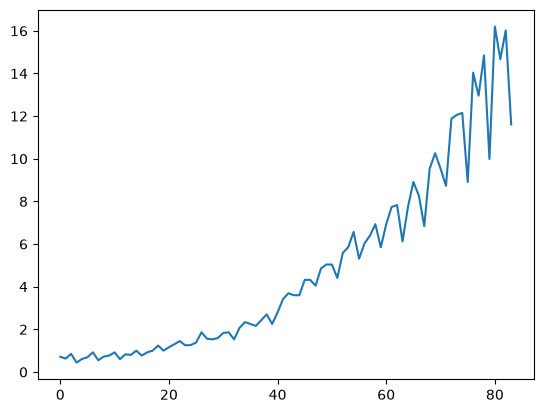

In [4]:
plt.plot(df['data'])

## 5. STL で3つに分ける

In [5]:
result = STL(df['data'], period=4).fit()

## 6. 4段のグラフを見る

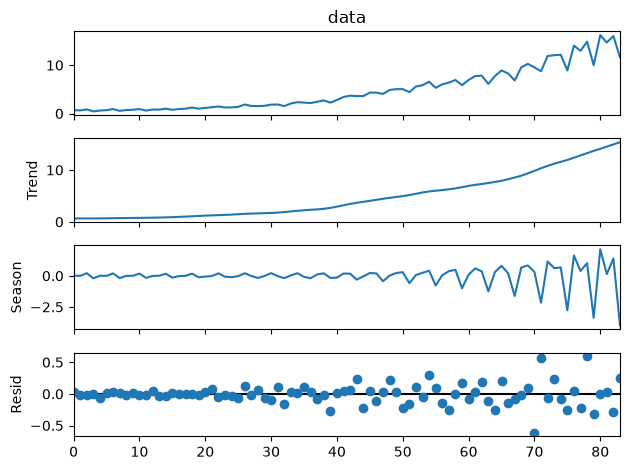

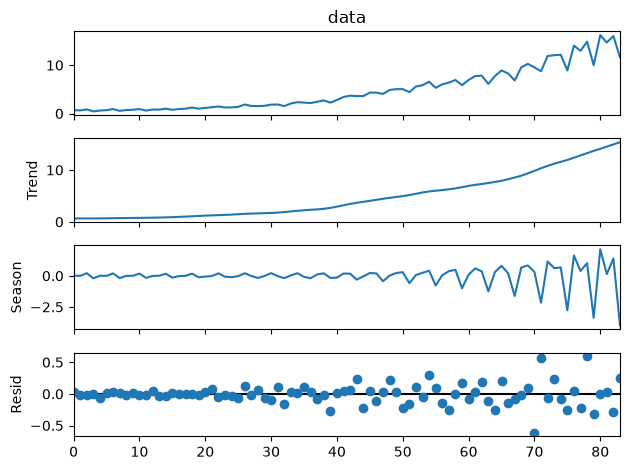

In [6]:
result.plot()

## 7. 足すと元に戻るか確かめる

In [7]:
back = result.trend + result.seasonal + result.resid
(back - df['data']).abs().max()

np.float64(1.7763568394002505e-15)

## やってみよう

※ セルを書き換えて ▶ を押したあとは、その下のセル（表やグラフ）も順に ▶ を押すと、結果が新しくなります。

- period は本当に大事？：5 のセルの period=4 を 2 に変えて、5・6 のセルを ▶。季節性の段が、プラスとマイナスの交互だけになります。数字で比べるなら、新しいセルに `result.resid.abs().mean()`（残差の大きさの平均）と書いて ▶。4 のとき 0.108、2 のとき 0.217（約2倍）、8 のとき 0.177。正しい周期（4つで1年）のとき、ズレがいちばん小さくなります。
- 未来のカンニングを見てみる：新しいセルに `r75 = STL(df['data'][:64], period=4).fit()` と書いて ▶（最初の64行＝1975年まで）。続けて `r75.seasonal[60:64]` と `result.seasonal[60:64]`（1975年の4つ）を見比べると、0.04・0.45・0.64・−1.19 と 0.09・0.59・0.36・−1.25。いちばん大きい差は 0.28。1980年までの全部で分解すると、1976年から先の答えが混ざっているからです。
- 困ったときのコツ：グラフの行の最後に `;` を付けると、グラフの上の英語の1行が消えます（グラフが2回出るときも直ります）。

---
コード: 本の著者 Marco Peixeiro のリポジトリ [marcopeix/TimeSeriesForecastingInPython](https://github.com/marcopeix/TimeSeriesForecastingInPython) のコードを元に、みらいグラフが改変しました（2026）。ライセンス: [Apache License 2.0](https://www.apache.org/licenses/LICENSE-2.0)

データと出典: Johnson & Johnson 四半期1株あたり利益 1960–1980（Shumway & Stoffer『Time Series Analysis and Its Applications』(Springer) ／ R datasets: JohnsonJohnson。本のリポジトリの data/jj.csv から取得）。